In [30]:
!pip install -q -U transformers accelerate bitsandbytes datasets

In [31]:
# ============ CONFIG ============
MODEL_NAME  = "Qwen/Qwen2.5-Coder-3B-Instruct"  
USE_4BIT    = False      
N_PROBLEMS  = 164         
MAX_ITER    = 3
FEEDBACK    = "smoke"    
REFORMULATE = True       
OUT_PATH    = "/kaggle/working/results_builder.json"

In [32]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
kw = dict(device_map="auto")
if USE_4BIT:
    kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True,
                                                   bnb_4bit_compute_dtype=torch.float16)
else:
    kw["torch_dtype"] = torch.float16      # T4 ne supporte pas bfloat16
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **kw).eval()
print("Modèle chargé sur :", model.device)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Modèle chargé sur : cuda:0


In [33]:
import re, sys, os, json, time, tempfile, subprocess
from collections import Counter

class LLM:
    def __init__(self):
        self.tokens = 0
    def chat(self, system, user, max_tokens=1024):
        msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
        text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        inputs = tok(text, return_tensors="pt").to(model.device)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_tokens, do_sample=False,
                                 pad_token_id=tok.eos_token_id)
        gen = out[0][inputs.input_ids.shape[1]:]
        self.tokens += inputs.input_ids.shape[1] + len(gen)
        return tok.decode(gen, skip_special_tokens=True)

ROUTER_SYS = ("Classe le message de l'utilisateur. Reponds uniquement par "
              "'CODE' si c'est une demande de generation/correction de code, sinon 'OTHER'.")
REFORM_SYS = ("Tu es un expert en prompt engineering pour la generation de code. "
              "Reformule la demande en un prompt precis et specialise : langage (Python), "
              "signature exacte de la fonction, entrees/sorties, cas limites, contraintes. "
              "Ne produis QUE le prompt reformule.")
BUILDER_SYS = ("Tu es un ingenieur Python expert. Reponds avec UN SEUL bloc ```python "
               "contenant le code complet (imports + fonction), sans explication, "
               "sans exemples d'utilisation, sans input().")

def is_code_request(llm, msg):
    return llm.chat(ROUTER_SYS, msg, max_tokens=5).strip().upper().startswith("CODE")

def reformulate(llm, msg):
    return llm.chat(REFORM_SYS, msg, max_tokens=512).strip()

def extract_code(text):
    m = re.findall(r"```(?:python)?\n(.*?)```", text, re.S)
    return (m[0] if m else text).strip()

def run_sandbox(code, extra="", timeout=10):
    try:
        compile(code, "<gen>", "exec")
    except SyntaxError as e:
        return False, "SyntaxError", f"{e.msg} (ligne {e.lineno})"
    with tempfile.TemporaryDirectory() as d:
        path = os.path.join(d, "sol.py")
        with open(path, "w") as f:
            f.write(code + "\n\n" + extra)
        try:
            p = subprocess.run([sys.executable, path], capture_output=True,
                               text=True, timeout=timeout, cwd=d)
        except subprocess.TimeoutExpired:
            return False, "Timeout", f"Execution > {timeout}s"
    if p.returncode == 0:
        return True, None, ""
    lines = p.stderr.strip().splitlines()
    last = lines[-1] if lines else "unknown"
    etype = "AssertionError" if "AssertionError" in p.stderr else (last.split(":")[0] if ":" in last else "RuntimeError")
    return False, etype, p.stderr[-1500:]

def solve(llm, message, problem, max_iter, feedback, reformulate_on):
    t0, trace = time.time(), []
    if not is_code_request(llm, message):
        return {"intent": "OTHER", "success": None, "iters": 0, "trace": [], "latency": time.time() - t0}
    prompt = reformulate(llm, message) if reformulate_on else message
    loop_extra = problem["test"] + f"\ncheck({problem['entry_point']})\n" if feedback == "tests" else ""
    user_msg, code = prompt, ""
    for i in range(1, max_iter + 1):
        code = extract_code(llm.chat(BUILDER_SYS, user_msg, max_tokens=768))
        ok, etype, err = run_sandbox(code, loop_extra)
        trace.append({"iter": i, "ok": ok, "error": etype})
        if ok:
            break
        user_msg = (f"{prompt}\n\nTon code precedent :\n```python\n{code}\n```\n"
                    f"a echoue avec {etype} :\n{err}\nCorrige-le. Renvoie le code complet.")
    final_extra = problem["test"] + f"\ncheck({problem['entry_point']})\n"
    final_ok, final_err, _ = run_sandbox(code, final_extra)
    return {"intent": "CODE", "success": final_ok, "final_error": final_err, "iters": len(trace),
            "first_try_ok": final_ok and len(trace) == 1, "trace": trace, "latency": time.time() - t0}

def compute_metrics(results, llm):
    code_res = [r for r in results if r["intent"] == "CODE"]
    n = len(code_res)
    succ = [r for r in code_res if r["success"]]
    first = [r for r in code_res if r.get("first_try_ok")]
    errs = Counter(t["error"] for r in code_res for t in r["trace"] if not t["ok"])
    return {
        "n_problems": n,
        "intent_accuracy_on_code": n / max(len(results), 1),
        "pass@1": len(first) / max(n, 1),
        "pass@final": len(succ) / max(n, 1),
        "gain_reparation": (len(succ) - len(first)) / max(n, 1),
        "avg_iterations": sum(r["iters"] for r in code_res) / max(n, 1),
        "avg_latency_s": sum(r["latency"] for r in results) / max(len(results), 1),
        "tokens_per_problem": llm.tokens / max(n, 1),
        "error_distribution": dict(errs),
        "success_by_iteration": {k: sum(1 for r in succ if r["iters"] == k) for k in range(1, 6)},
    }

In [34]:
from datasets import load_dataset
ds = load_dataset("openai/openai_humaneval", split="test").select(range(N_PROBLEMS))

# Reprise automatique si la session a été coupée
results, done = [], set()
if os.path.exists(OUT_PATH):
    results = json.load(open(OUT_PATH))["results"]
    done = {r["task_id"] for r in results}
    print(f"Reprise : {len(done)} problèmes déjà faits")

llm = LLM()
for k, p in enumerate(ds):
    if p["task_id"] in done:
        continue
    r = solve(llm, p["prompt"], p, MAX_ITER, FEEDBACK, REFORMULATE)
    r["task_id"] = p["task_id"]
    results.append(r)
    print(f"[{k+1}/{len(ds)}] {p['task_id']}  success={r['success']}  iters={r['iters']}  {r['latency']:.0f}s")
    json.dump({"config": dict(MODEL_NAME=MODEL_NAME, MAX_ITER=MAX_ITER, FEEDBACK=FEEDBACK,
                              REFORMULATE=REFORMULATE), "results": results},
              open(OUT_PATH, "w"), ensure_ascii=False)

Reprise : 164 problèmes déjà faits


In [35]:
import pandas as pd
m = compute_metrics(results, llm)
for k, v in m.items():
    print(f"{k:28s} {v}")

n_problems                   164
intent_accuracy_on_code      1.0
pass@1                       0.8292682926829268
pass@final                   0.8292682926829268
gain_reparation              0.0
avg_iterations               1.0
avg_latency_s                25.139204896077878
tokens_per_problem           0.0
error_distribution           {}
success_by_iteration         {1: 136, 2: 0, 3: 0, 4: 0, 5: 0}


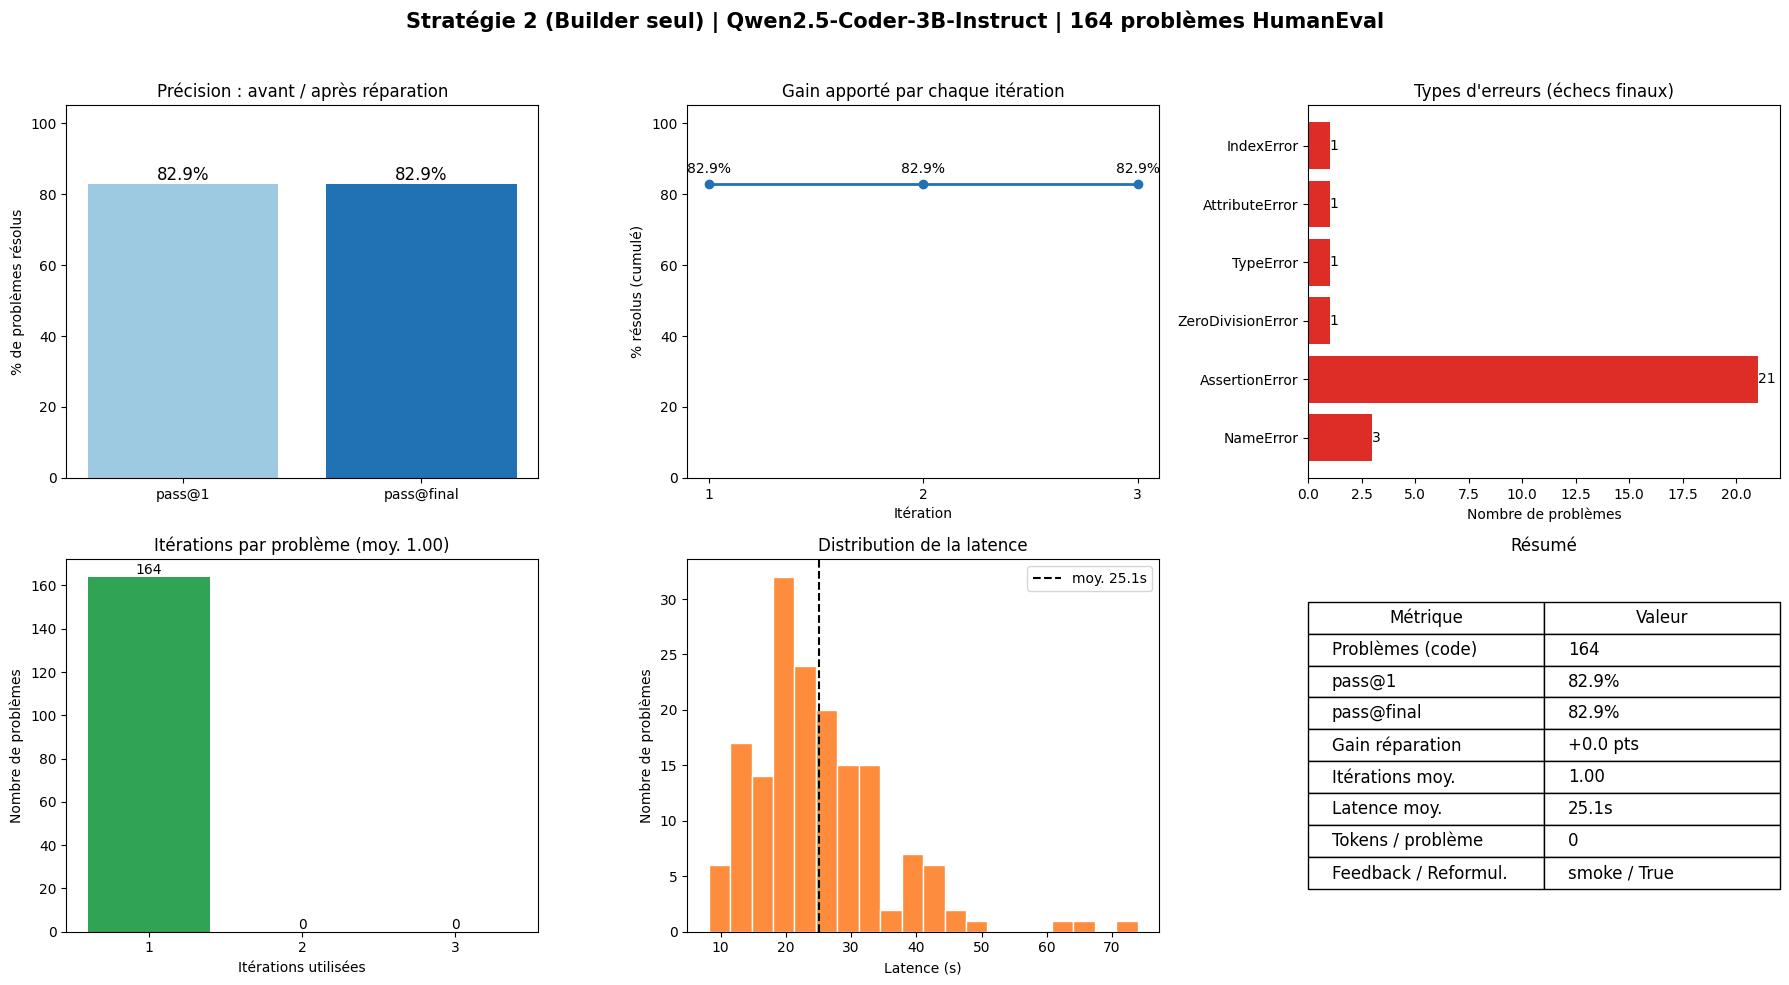

In [36]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

code_res = [r for r in results if r["intent"] == "CODE"]
n = len(code_res)
m = compute_metrics(results, llm)

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(f"Stratégie 2 (Builder seul) | {MODEL_NAME.split('/')[-1]} | {n} problèmes HumanEval",
             fontsize=15, fontweight="bold")


bars = ax[0, 0].bar(["pass@1", "pass@final"], [m["pass@1"] * 100, m["pass@final"] * 100],
                    color=["#9ecae1", "#2171b5"])
ax[0, 0].bar_label(bars, fmt="%.1f%%", fontsize=12)
ax[0, 0].set_ylim(0, 105); ax[0, 0].set_ylabel("% de problèmes résolus")
ax[0, 0].set_title("Précision : avant / après réparation")


ks = list(range(1, MAX_ITER + 1))
solved = [sum(1 for r in code_res if r["success"] and r["iters"] == k) for k in ks]
cum = np.cumsum(solved) / max(n, 1) * 100
ax[0, 1].plot(ks, cum, marker="o", linewidth=2, color="#2171b5")
for x, y in zip(ks, cum):
    ax[0, 1].annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax[0, 1].set_xticks(ks); ax[0, 1].set_ylim(0, 105)
ax[0, 1].set_xlabel("Itération"); ax[0, 1].set_ylabel("% résolus (cumulé)")
ax[0, 1].set_title("Gain apporté par chaque itération")


fails = Counter((r.get("final_error") or "Inconnu") for r in code_res if not r["success"])
if fails:
    ax[0, 2].barh(list(fails.keys()), list(fails.values()), color="#de2d26")
    ax[0, 2].bar_label(ax[0, 2].containers[0])
else:
    ax[0, 2].text(0.5, 0.5, "Aucun échec", ha="center", va="center", fontsize=14)
ax[0, 2].set_title("Types d'erreurs (échecs finaux)"); ax[0, 2].set_xlabel("Nombre de problèmes")


it = Counter(r["iters"] for r in code_res)
ax[1, 0].bar([str(k) for k in ks], [it.get(k, 0) for k in ks], color="#31a354")
ax[1, 0].bar_label(ax[1, 0].containers[0])
ax[1, 0].set_xlabel("Itérations utilisées"); ax[1, 0].set_ylabel("Nombre de problèmes")
ax[1, 0].set_title(f"Itérations par problème (moy. {m['avg_iterations']:.2f})")


lat = [r["latency"] for r in results]
ax[1, 1].hist(lat, bins=20, color="#fd8d3c", edgecolor="white")
ax[1, 1].axvline(np.mean(lat), color="k", linestyle="--", label=f"moy. {np.mean(lat):.1f}s")
ax[1, 1].set_xlabel("Latence (s)"); ax[1, 1].set_ylabel("Nombre de problèmes")
ax[1, 1].set_title("Distribution de la latence"); ax[1, 1].legend()


rows = [["Problèmes (code)", f"{n}"],
        ["pass@1", f"{m['pass@1'] * 100:.1f}%"],
        ["pass@final", f"{m['pass@final'] * 100:.1f}%"],
        ["Gain réparation", f"+{m['gain_reparation'] * 100:.1f} pts"],
        ["Itérations moy.", f"{m['avg_iterations']:.2f}"],
        ["Latence moy.", f"{m['avg_latency_s']:.1f}s"],
        ["Tokens / problème", f"{m['tokens_per_problem']:.0f}"],
        ["Feedback / Reformul.", f"{FEEDBACK} / {REFORMULATE}"]]
ax[1, 2].axis("off")
tbl = ax[1, 2].table(cellText=rows, colLabels=["Métrique", "Valeur"], loc="center", cellLoc="left")
tbl.auto_set_font_size(False); tbl.set_fontsize(12); tbl.scale(1, 1.8)
ax[1, 2].set_title("Résumé")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("/kaggle/working/performance.png", dpi=150, bbox_inches="tight")
plt.show()